In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


# PART 1

In [2]:
import pandas as pd

df_path = r"./statlog+german+credit+data/german.data"
columns = [
    'checking_account',
    'duration',
    'credit_history',
    'purpose',
    'credit_amount',
    'savings_account',
    'employment',
    'installment_rate',
    'personal_status_sex',
    'other_debtors',
    'residence_since',
    'property',
    'age',
    'other_installment_plans',
    'housing',
    'existing_credits',
    'job',
    'num_dependents',
    'telephone',
    'foreign_worker',
    'target'
]
df = pd.read_csv(df_path,sep=r'\s+',header=None,names=columns)
df['target'] = df['target'].map({
    1: 0,  # عدم نکول
    2: 1   # نکول
})
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_account         1000 non-null   object
 1   duration                 1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings_account          1000 non-null   object
 6   employment               1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14  housing                  1000 non-null   

In [3]:
df.isna().sum()

checking_account           0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings_account            0
employment                 0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
num_dependents             0
telephone                  0
foreign_worker             0
target                     0
dtype: int64

In [4]:
df_copy = df.copy()

# Feature matrix: only the target is excluded
features = df.drop(columns=["target"])

# 7 numerical and 13 categorical features, as documented in german.doc
numerical_cols = features.select_dtypes(include=[np.number]).columns
categorical_cols = features.select_dtypes(exclude=[np.number]).columns

print("Numerical:", list(numerical_cols))
print("Categorical:", list(categorical_cols))

Numerical: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical: ['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


there is no null value in df. also only target column must seperate from other and there is no other column that is directly related to the goal and could lead to information leakage. so we only seperate target from others.

### Outlier Analysis


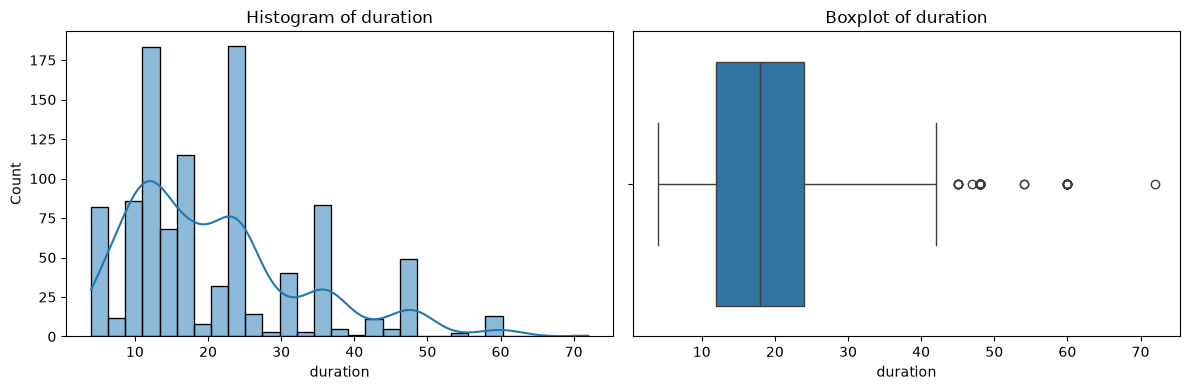

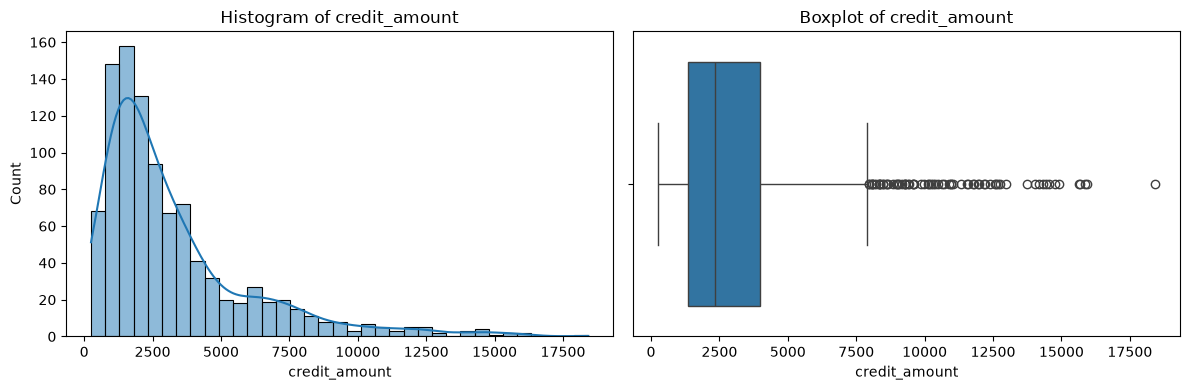

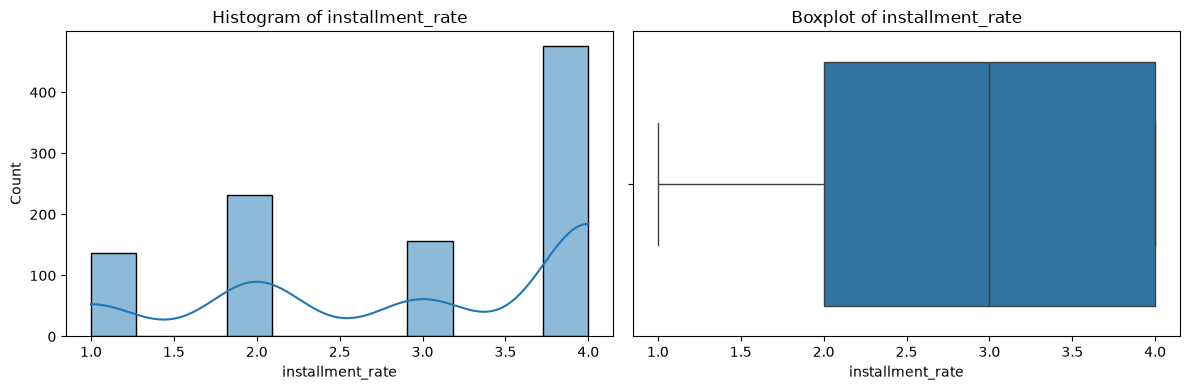

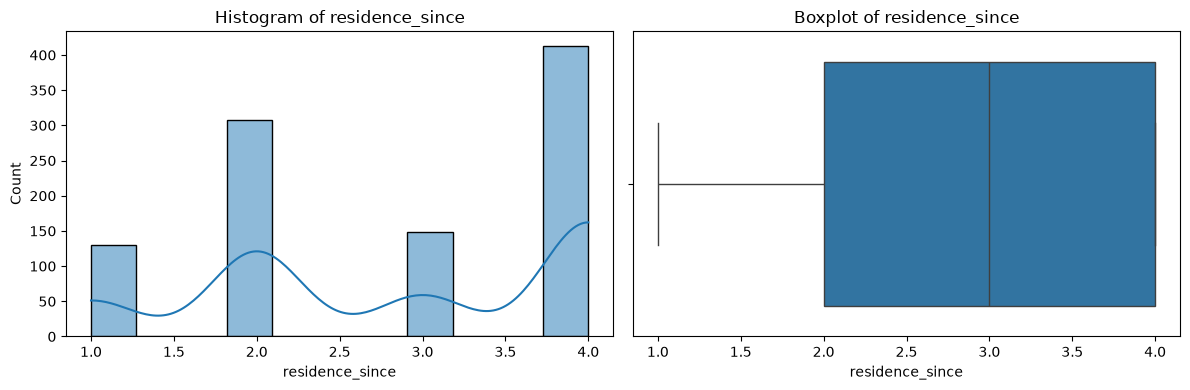

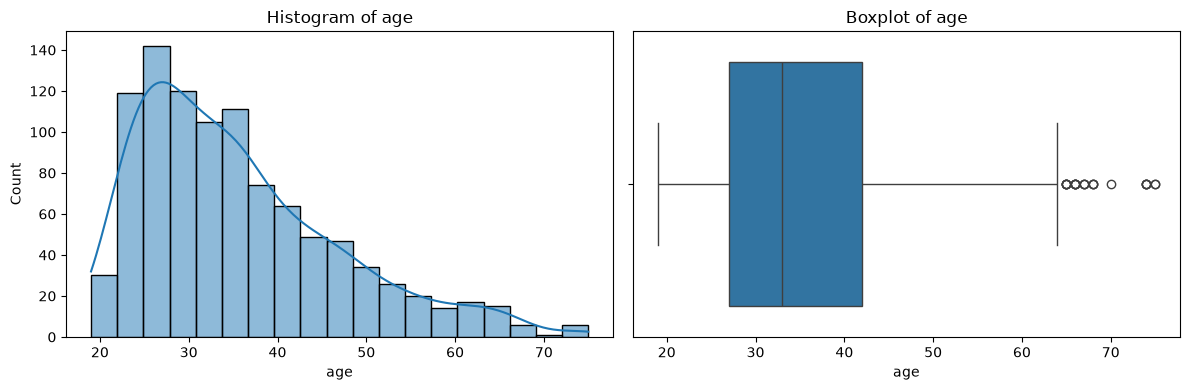

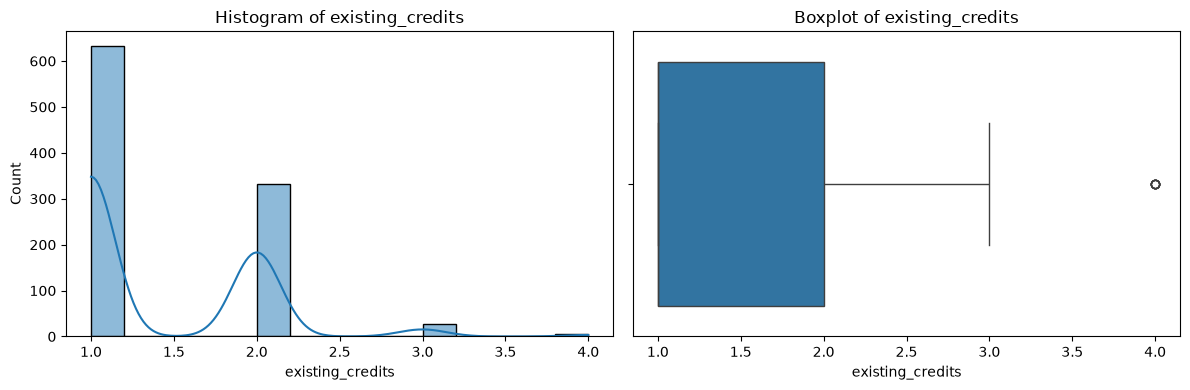

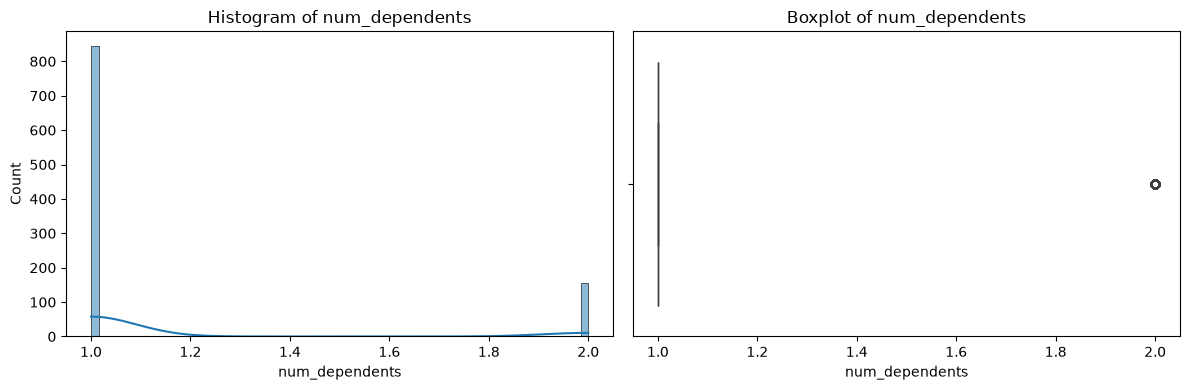

In [5]:
for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    # Histogram
    sns.histplot(features[col], kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram of {col}")
    # Boxplot
    sns.boxplot(x=features[col], ax=axes[1])
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [6]:


df_copy["Is_Outlier"] = False

outlier_report = []

for col in numerical_cols:
    q1 = df_copy[col].quantile(0.25)
    q3 = df_copy[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    col_outlier = (
        (df_copy[col] < lower) |
        (df_copy[col] > upper)
    )

    df_copy["Is_Outlier"] = (
        df_copy["Is_Outlier"] |
        col_outlier
    )

    count = ((df_copy[col] < lower) | (df_copy[col] > upper)).sum()

    outlier_report.append({
        "Feature": col,
        "Min": df_copy[col].min(),
        "Max": df_copy[col].max(),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Candidate_Outliers": count,
        "Outlier_Percent": round(count / len(df_copy) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_report)
outlier_report.sort_values("Outlier_Percent", ascending=False)

,Feature,Min,Max,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Candidate_Outliers,Outlier_Percent
6,num_dependents,1,2,1.0,1.00,0.00,1.000,1.000,155,15.5
1,credit_amount,250,18424,1365.5,3972.25,2606.75,-2544.625,7882.375,72,7.2
0,duration,4,72,12.0,24.00,12.00,-6.000,42.000,70,7.0
4,age,19,75,27.0,42.00,15.00,4.500,64.500,23,2.3
5,existing_credits,1,4,1.0,2.00,1.00,-0.500,3.500,6,0.6
2,installment_rate,1,4,2.0,4.00,2.00,-1.000,7.000,0,0.0
3,residence_since,1,4,2.0,4.00,2.00,-1.000,7.000,0,0.0


Amount:
The histogram displays a positively skewed (right-skewed) distribution, indicating that the majority of loan durations are concentrated in the lower ranges—specifically between approximately 10 and 25 months. As the loan duration increases, the frequency of observations generally decreases. The highest frequencies are observed at the 12-month and 24-month marks. Furthermore, there are outliers corresponding to loans with durations exceeding 40 months; while these are classified as outliers from a statistical perspective, they may represent specific types of credit facilities. Consequently, we have chosen not to exclude them as invalid data.
Loan Amount:
Similar to loan duration, the histogram for this variable is right-skewed, showing that loan amounts are predominantly concentrated in the lower ranges. Additionally, outliers appear for loan amounts exceeding approximately 7,500, which likewise point to specific types of credit facilities.
existence of specialized credit facilities.
Given that these features are expected to have a significant impact on predictive performance, analyzing their outliers will be crucial for understanding the model's behavior in subsequent stages.
About installment_rate and residence_since , there is no outlier for them.However, an examination of their bar plots—along with a re-evaluation of the data—reveals that although these features are technically numeric, they have been transformed into categorical variables through a binning process.
Regarding age, the distribution is right-skewed, indicating a lower density of borrowers in the higher age ranges. Additionally, there are some outliers beyond the age of 70.however, since the maximum recorded age is 75, these entries are not illogical and do not represent invalid data.
Existing_credits:
show most of customers have only 1 loan.
Num Dependents:
show most of customers have only 1 dependent.

### Numerical Features Analysis


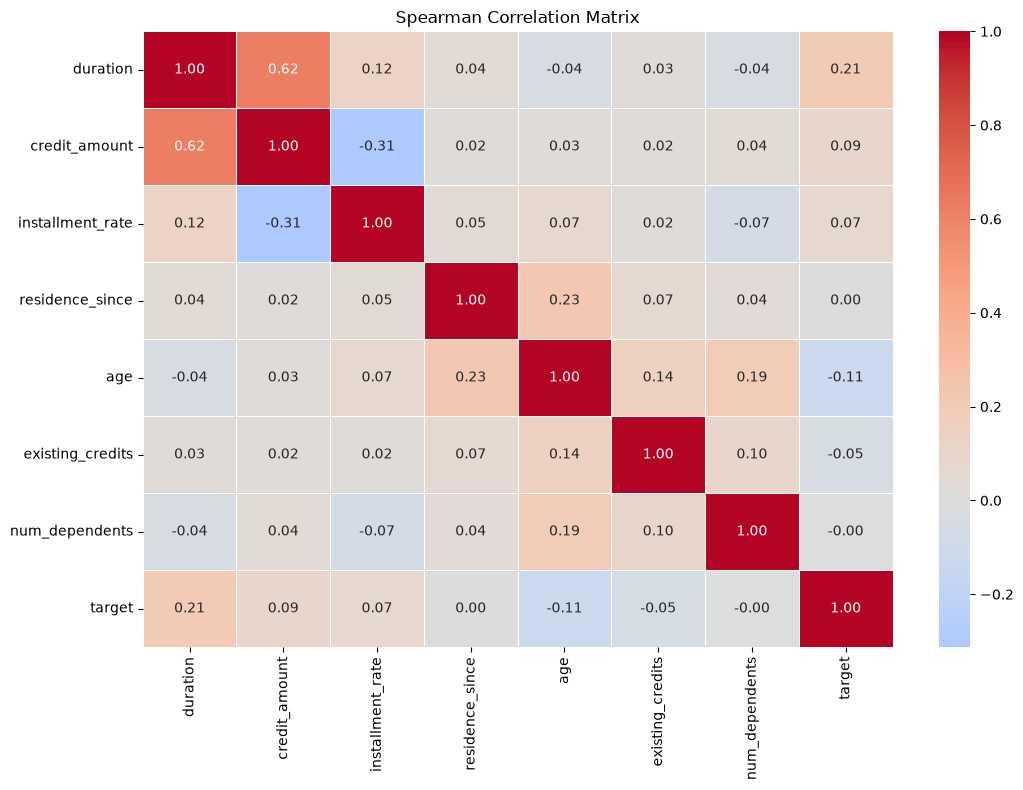

In [7]:
corr_data = df[list(numerical_cols) + ["target"]]
corr_matrix = corr_data.corr(method='spearman')
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Spearman Correlation Matrix')
plt.tight_layout()
plt.show()

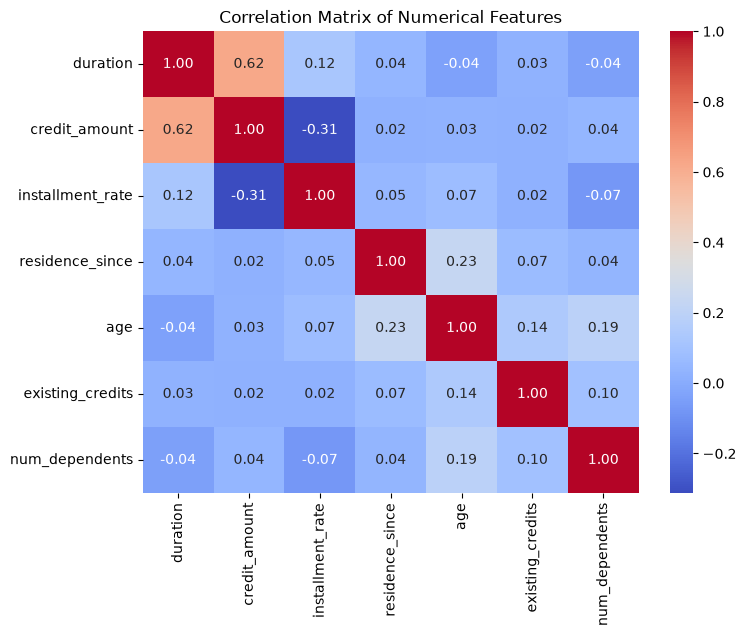

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[list(numerical_cols)].corr(method='spearman'), annot=True, cmap='coolwarm', fmt='.2f'
)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [9]:
df.groupby('target')['duration'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
target,,,,,
0,700,19.207143,18.0,4,60
1,300,24.860000,24.0,6,72


Analysis of Feature Correlations:
The strongest positive correlation exists between  duration  and  credit amount . This relationship indicates that, in general, as the credit amount increases, the repayment duration also tends to increase. Consequently, to reduce the risk of default, it might be advisable to promote smaller loans with shorter repayment periods. However, confirming this hypothesis requires analyzing the correlations between the target variable and the features.
The strongest negative correlation is observed between  credit amount  and  installment rate , indicating that as the  installment rate  value increases, the  credit amount  tends to decrease.

Analysis of Feature-Target Correlations:
No very strong correlation is observed between the target variable and the features. Nevertheless, the strongest positive correlation is associated with  duration  (which influences the likelihood of default), while the strongest negative correlation is associated with  age  (which is linked to a lower likelihood of default). This may reflect greater income stability among older segments of the population. It should be noted, however, that the  age  distribution is right-skewed, indicating that the majority of the borrowers in the dataset are younger. Therefore, one should not rely solely on this negative correlation.


### Categorical Features Analysis



In [10]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

def cramers_v(feature, target):
    table = pd.crosstab(feature, target)
    if min(table.shape) < 2:
        return np.nan, np.nan, np.nan, np.nan
    chi2, p_value, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return chi2, p_value, dof, v

rows = []
for col in categorical_cols:
    chi2, p_value, dof, v = cramers_v(df[col], df["target"])
    rows.append({
        "Feature": col,
        "Chi2": round(chi2, 1),
        "DoF": dof,
        "p-value": p_value,
        "Cramers_V": round(v, 3),
    })

association = (
    pd.DataFrame(rows)
    .sort_values("Cramers_V", ascending=False)
    .reset_index(drop=True)
)
association

,Feature,Chi2,DoF,p-value,Cramers_V
0,checking_account,123.7,3,1.218902e-26,0.352
1,credit_history,61.7,4,1.279187e-12,0.248
2,savings_account,36.1,4,2.761214e-07,0.190
3,purpose,33.4,9,1.157491e-04,0.183
4,property,23.7,3,2.858442e-05,0.154
5,employment,18.4,4,1.045452e-03,0.136
6,housing,18.2,2,1.116747e-04,0.135
7,other_installment_plans,12.8,2,1.629318e-03,0.113
8,personal_status_sex,9.6,3,2.223801e-02,0.098
9,other_debtors,6.6,2,3.605595e-02,0.082


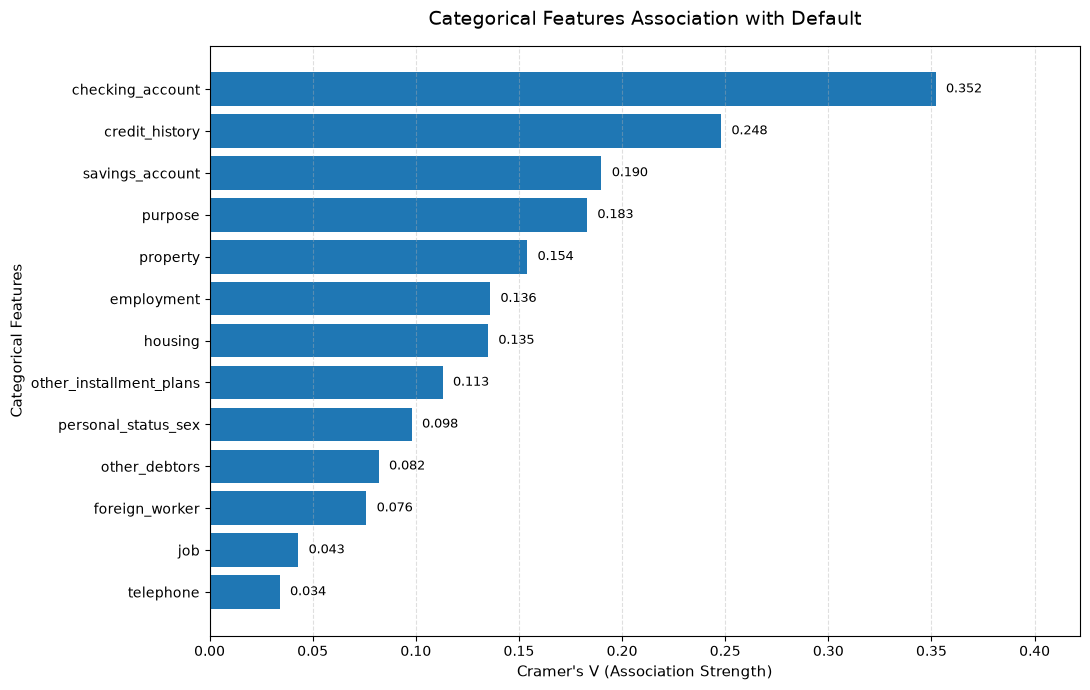

In [11]:

import matplotlib.pyplot as plt

# Sort features by Cramer's V
plot_data = association.sort_values("Cramers_V", ascending=True)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    plot_data["Feature"],
    plot_data["Cramers_V"]
)

# Display values at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va="center",
        fontsize=9
    )

plt.title("Categorical Features Association with Default",
          fontsize=14, pad=15)

plt.xlabel("Cramer's V (Association Strength)", fontsize=11)
plt.ylabel("Categorical Features", fontsize=11)

plt.xlim(0, association["Cramers_V"].max() + 0.07)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()


We found that "checking_account" has the strongest association with the target among all categorical features.Therefore, we plot a "stacked bar chart" to compare the number of default and non-default customers across different checking account categories and identify which account status is associated with a higher default rate.
after that we also plot for "credit history" as same as "checking_account".

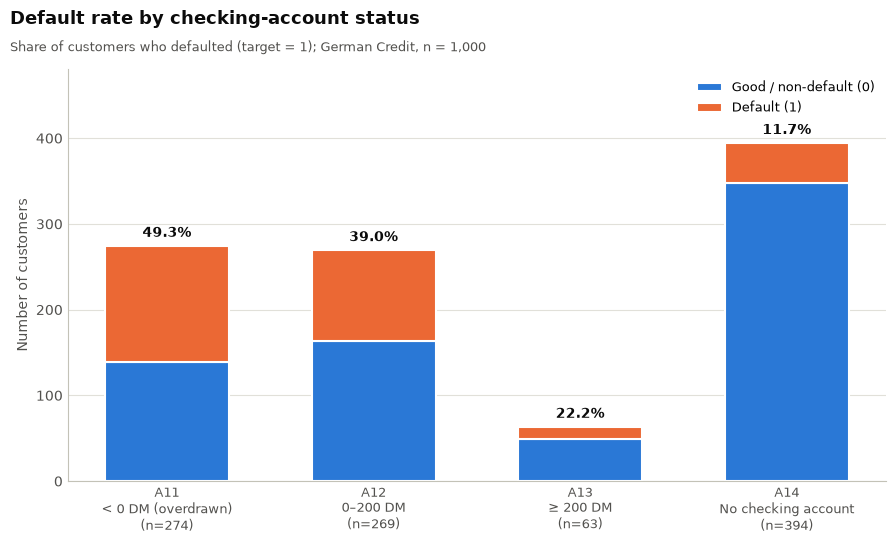

In [12]:
GOOD_COLOR = "#2a78d6"   # non-default
BAD_COLOR = "#eb6834"    # default

def plot_stacked_default(col, short_labels, ax):
    """Stacked good/bad counts per category, with the default rate annotated."""
    table = pd.crosstab(df[col], df["target"]).reindex(
        index=list(short_labels), columns=[0, 1], fill_value=0
    )
    x = np.arange(len(table))
    good = table[0].to_numpy()
    bad = table[1].to_numpy()
    totals = good + bad

    ax.bar(x, good, width=0.6, color=GOOD_COLOR, edgecolor="white",
           linewidth=1.5, label="Good / non-default (0)")
    ax.bar(x, bad, width=0.6, bottom=good, color=BAD_COLOR, edgecolor="white",
           linewidth=1.5, label="Default (1)")

    for xi, total, default_count in zip(x, totals, bad):
        ax.text(xi, total + 7, f"{default_count / total:.1%}", ha="center",
                va="bottom", fontsize=10, fontweight="bold", color="#0b0b0b")

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{code}\n{meaning}\n(n={int(total)})"
         for (code, meaning), total in zip(short_labels.items(), totals)],
        fontsize=9, color="#52514e",
    )
    ax.set_ylim(0, totals.max() * 1.22)
    ax.set_ylabel("Number of customers", color="#52514e")
    ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(axis="both", colors="#52514e", length=0)
    ax.legend(frameon=False, loc="upper right", fontsize=9)

checking_labels = {
    "A11": "< 0 DM (overdrawn)",
    "A12": "0–200 DM",
    "A13": "≥ 200 DM",
    "A14": "No checking account",
}

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_stacked_default("checking_account", checking_labels, ax)

fig.text(0.01, 0.98, "Default rate by checking-account status",
         fontsize=13, fontweight="bold", color="#0b0b0b", ha="left", va="top")
fig.text(0.01, 0.925,
         "Share of customers who defaulted (target = 1); German Credit, n = 1,000",
         fontsize=9.5, color="#52514e", ha="left", va="top")

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

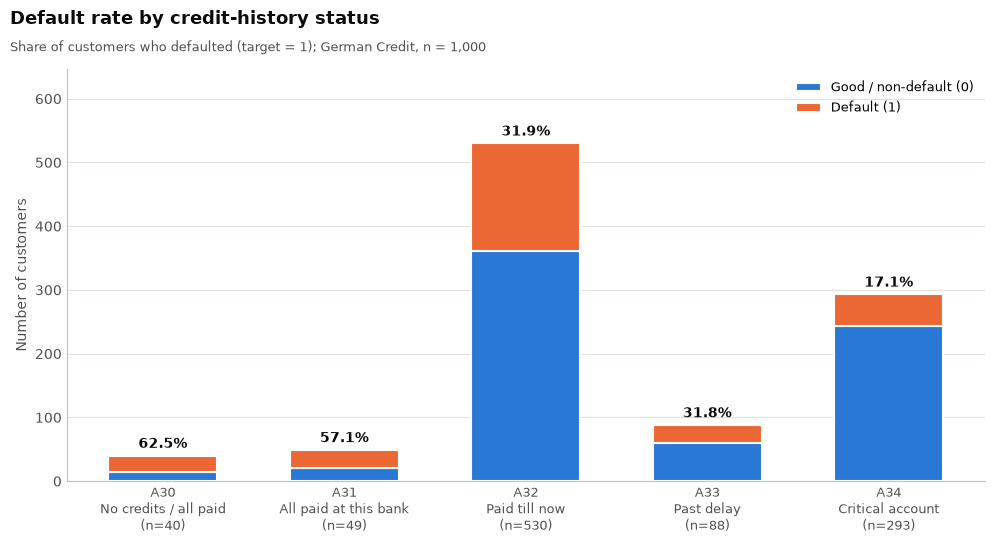

In [13]:
credit_history_labels = {
    "A30": "No credits / all paid",
    "A31": "All paid at this bank",
    "A32": "Paid till now",
    "A33": "Past delay",
    "A34": "Critical account",
}

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_stacked_default("credit_history", credit_history_labels, ax)

fig.text(0.01, 0.98, "Default rate by credit-history status",
         fontsize=13, fontweight="bold", color="#0b0b0b", ha="left", va="top")
fig.text(0.01, 0.925,
         "Share of customers who defaulted (target = 1); German Credit, n = 1,000",
         fontsize=9.5, color="#52514e", ha="left", va="top")

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()



`checking_account` has the strongest relationship with default. Customers with a negative checking account balance (A11) have the highest default rate (49.3%). This rate decreases to 11.7% for customers with no checking account (A14).

`credit_history` also shows a strong relationship with default. Customers in groups A30 and A31 have the highest default rates (62.5% and 57.1%), while group A34 has the lowest rate (17.1%). However, these groups contain relatively few customers, so their results should be interpreted carefully.

`savings_account` and `purpose` also show some relationship with default.

Overall, categorical features, especially `checking_account` and `credit_history`, show stronger relationships with default than the numerical features in the initial analysis. these features will be examined further during the modeling stage.

In [14]:
print(df['target'].value_counts(normalize=True))

target
0    0.7
1    0.3
Name: proportion, dtype: float64


The target class is imbalanced.

In [15]:
n_samples = len(df)
n_features = features.shape[1]
good = int((df["target"] == 0).sum())
bad = int((df["target"] == 1).sum())

summary = pd.DataFrame({
    "Metric": [
        "Samples",
        "Features",
        "Good-standing / non-default (0)",
        "Default / bad-standing (1)",
        "Class imbalance ratio (good : bad)",
    ],
    "Value": [
        f"{n_samples:,}",
        f"{n_features}",
        f"{good:,} ({good / n_samples:.0%})",
        f"{bad:,} ({bad / n_samples:.0%})",
        f"{good / bad:.2f} : 1",
    ],
})

summary

,Metric,Value
0,Samples,"1,000"
1,Features,20
2,Good-standing / non-default (0),700 (70%)
3,Default / bad-standing (1),300 (30%)
4,Class imbalance ratio (good : bad),2.33 : 1


# PART 2 :

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

In [17]:
df.head()

,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,1


Regarding the "telephone" feature,even without performing a statistical analysis it is evident that it is not a suitable discriminator for our problem. therefore,we drop it from our dataset.

In [18]:
df = df.drop(columns=["telephone"])

In [19]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

split_report = pd.DataFrame({
    "Set": ["Train", "Test"],
    "Rows": [len(X_train), len(X_test)],
    "Share": [f"{len(X_train) / len(X):.0%}", f"{len(X_test) / len(X):.0%}"],
    "Good (0)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "Bad (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
    "Default rate": [f"{y_train.mean():.1%}", f"{y_test.mean():.1%}"],
})

split_report

,Set,Rows,Share,Good (0),Bad (1),Default rate
0,Train,800,80%,560,240,30.0%
1,Test,200,20%,140,60,30.0%


### Making New Financial Features

1. `monthly_installment` = `credit_amount / duration`**

The average monthly repayment over the life of the loan. A larger installment consumes more of the borrower's monthly cash flow, so it is a direct affordability measure. Its marginal direction is not stable across samples (see the note below), so the ranking treats it as a non-causal signal rather than a rule.


Some decisions regarding the nature of the features have been made based on documentation available at the following URL: "https://dutangc.github.io/CASdatasets/reference/credit.html".

In [20]:
def add_financial_features(frame):
    out = frame.copy()
    out["monthly_installment"] = out["credit_amount"] / out["duration"]
    return out


X_train_fe = add_financial_features(X_train)
X_test_fe = add_financial_features(X_test)

engineered_summary = (
    X_train_fe
    .assign(target=y_train)
    .groupby("target")[["monthly_installment"]]
    .mean()
    .T
    .rename(columns={0: "Good (0)", 1: "Bad (1)"})
)
engineered_summary["Difference (Bad - Good)"] = (
    engineered_summary["Bad (1)"] - engineered_summary["Good (0)"]
)

print(f"Train rows: {len(X_train_fe):,} | Test rows: {len(X_test_fe):,}")
print(f"New columns: {[c for c in X_train_fe.columns if c not in X.columns]}")
print(f"Missing after engineering: train={int(X_train_fe.isna().sum().sum())}, "
      f"test={int(X_test_fe.isna().sum().sum())}")
engineered_summary.round(2)

Train rows: 800 | Test rows: 200
New columns: ['monthly_installment']
Missing after engineering: train=0, test=0


target,Good (0),Bad (1),Difference (Bad - Good)
monthly_installment,165.72,155.13,-10.58


###**Encoding.** The 12 categorical features are divided into ordinal and nominal variables:

| Group | Features | Encoding |
|---|---|---|
| Ordinal (3) | `checking_account`, `savings_account`, `employment` | `OrdinalEncoder` with predefined category orders |
| Nominal (10) | `credit_history`, `purpose`, `personal_status_sex`, `other_debtors`, `property`, `other_installment_plans`, `housing`, `foreign_worker`, `job` | `OneHotEncoder(handle_unknown="ignore")` |
| Numeric (8) | 7 original numerical features + `monthly_installment` | Median imputation and `StandardScaler` |

Ordinal encoding preserves the natural order of account balance and employment-duration categories. Nominal encoding avoids imposing artificial numerical relationships between unrelated categories. Unknown categories are handled safely by the encoders.

All preprocessing steps are fitted exclusively on `X_train_fe` and then applied to both training and test data using a single `ColumnTransformer`, preventing data leakage.

In [21]:
missing_audit = pd.DataFrame({
    "Set": ["Train", "Test"],
    "Rows": [len(X_train_fe), len(X_test_fe)],
    "Missing cells": [
        int(X_train_fe.isna().sum().sum()),
        int(X_test_fe.isna().sum().sum()),
    ],
    "Columns with any missing": [
        int((X_train_fe.isna().sum() > 0).sum()),
        int((X_test_fe.isna().sum() > 0).sum()),
    ],
})

missing_audit

,Set,Rows,Missing cells,Columns with any missing
0,Train,800,0,0
1,Test,200,0,0


In [22]:
ordinal_features = {
    "checking_account": ["A11", "A12", "A13", "A14"],
    "savings_account": ["A65", "A61", "A62", "A63", "A64"],
    "employment": ["A71", "A72", "A73", "A74", "A75"],
}
ordinal_cols = list(ordinal_features)

nominal_cols = [
    "credit_history",
    "purpose",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "foreign_worker",
    "job"
]

numerical_features = list(numerical_cols) + ["monthly_installment"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

nominal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(
        categories=[ordinal_features[col] for col in ordinal_cols],
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("nom", nominal_transformer, nominal_cols),
        ("ord", ordinal_transformer, ordinal_cols),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

In [23]:
X_train_processed = preprocessor.fit_transform(X_train_fe)
X_test_processed = preprocessor.transform(X_test_fe)

assert X_train_processed.columns.is_unique, "Duplicate output column names"
assert int(X_train_processed.isna().sum().sum()) == 0
assert int(X_test_processed.isna().sum().sum()) == 0

n_onehot = X_train_processed.shape[1] - len(numerical_features) - len(ordinal_cols)

print(f"Train matrix: {X_train_processed.shape}")
print(f"Test matrix:  {X_test_processed.shape}")
print(f"Output columns: {len(numerical_features)} numeric + {n_onehot} one-hot + "
      f"{len(ordinal_cols)} ordinal")
print(f"All output columns numeric: {X_train_processed.dtypes.eq('float64').all()}")

scale_check = pd.DataFrame({
    "Train mean": X_train_processed[numerical_features].mean(),
    "Train std": X_train_processed[numerical_features].std(),
    "Test mean": X_test_processed[numerical_features].mean(),
    "Test std": X_test_processed[numerical_features].std(),
})

scale_check.round(2)

Train matrix: (800, 49)
Test matrix:  (200, 49)
Output columns: 8 numeric + 38 one-hot + 3 ordinal
All output columns numeric: True


,Train mean,Train std,Test mean,Test std
duration,0.0,1.0,0.06,1.10
credit_amount,0.0,1.0,0.15,1.25
installment_rate,-0.0,1.0,0.14,0.97
residence_since,-0.0,1.0,0.07,0.97
age,0.0,1.0,0.10,1.14
existing_credits,0.0,1.0,-0.00,1.09
num_dependents,0.0,1.0,-0.07,0.93
monthly_installment,0.0,1.0,0.22,2.16


In [24]:
display(X_train_processed.head())
X_train_processed.head()


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,num_dependents,monthly_installment,credit_history_A30,credit_history_A31,credit_history_A32,credit_history_A33,credit_history_A34,purpose_A40,purpose_A41,purpose_A410,purpose_A42,purpose_A43,purpose_A44,purpose_A45,purpose_A46,purpose_A48,purpose_A49,personal_status_sex_A91,personal_status_sex_A92,personal_status_sex_A93,personal_status_sex_A94,other_debtors_A101,other_debtors_A102,other_debtors_A103,property_A121,property_A122,property_A123,property_A124,other_installment_plans_A141,other_installment_plans_A142,other_installment_plans_A143,housing_A151,housing_A152,housing_A153,foreign_worker_A201,foreign_worker_A202,job_A171,job_A172,job_A173,job_A174,checking_account,savings_account,employment
828,1.289592,1.925766,0.052281,1.053413,1.057784,-0.718745,-0.436436,0.592795,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0
997,-0.742595,-0.892853,0.942164,1.053413,0.242449,-0.718745,-0.436436,-0.820980,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,3.0,1.0,4.0
148,1.289592,0.816433,0.052281,-0.747293,-0.663479,1.045047,-0.436436,-0.114689,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,2.0
735,1.289592,0.299568,0.052281,-0.747293,-0.572886,-0.718745,-0.436436,-0.444323,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
130,2.305686,1.982655,-1.727486,-0.747293,-1.025850,-0.718745,-0.436436,0.122631,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,3.0


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,num_dependents,monthly_installment,credit_history_A30,credit_history_A31,credit_history_A32,credit_history_A33,credit_history_A34,purpose_A40,purpose_A41,purpose_A410,purpose_A42,purpose_A43,purpose_A44,purpose_A45,purpose_A46,purpose_A48,purpose_A49,personal_status_sex_A91,personal_status_sex_A92,personal_status_sex_A93,personal_status_sex_A94,other_debtors_A101,other_debtors_A102,other_debtors_A103,property_A121,property_A122,property_A123,property_A124,other_installment_plans_A141,other_installment_plans_A142,other_installment_plans_A143,housing_A151,housing_A152,housing_A153,foreign_worker_A201,foreign_worker_A202,job_A171,job_A172,job_A173,job_A174,checking_account,savings_account,employment
828,1.289592,1.925766,0.052281,1.053413,1.057784,-0.718745,-0.436436,0.592795,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0
997,-0.742595,-0.892853,0.942164,1.053413,0.242449,-0.718745,-0.436436,-0.820980,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,3.0,1.0,4.0
148,1.289592,0.816433,0.052281,-0.747293,-0.663479,1.045047,-0.436436,-0.114689,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,2.0
735,1.289592,0.299568,0.052281,-0.747293,-0.572886,-0.718745,-0.436436,-0.444323,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
130,2.305686,1.982655,-1.727486,-0.747293,-1.025850,-0.718745,-0.436436,0.122631,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,3.0


In [25]:
df.columns

Index(['checking_account', 'duration', 'credit_history', 'purpose',
       'credit_amount', 'savings_account', 'employment', 'installment_rate',
       'personal_status_sex', 'other_debtors', 'residence_since', 'property',
       'age', 'other_installment_plans', 'housing', 'existing_credits', 'job',
       'num_dependents', 'foreign_worker', 'target'],
      dtype='object')

### 2.3 The Three Key Discriminators

Every raw and engineered feature is ranked on the **training set only** with three complementary views:

1. **Univariate out-of-fold ROC-AUC (primary).** For numeric features, the feature itself is the score. For categorical features, each category is replaced by its default rate estimated on 4 of 5 folds and evaluated on the held-out fold, giving every feature a leakage-free AUC. AUC measures exactly the deliverable — the power to separate good (0) from bad (1) borrowers. Values below 0.5 are flipped with `max(AUC, 1 - AUC)` so every feature is scored by the strength of its signal rather than its direction.
2. **Mutual information (supporting).** `mutual_info_classif` on raw feature codes, averaged over five random seeds. MI captures non-linear dependence but is noisy at n = 800, so it is a cross-check, not the final ranking.
3. **Random-forest importance (multivariate cross-check).** A shallow `RandomForestClassifier` (`max_depth=5`, `class_weight="balanced"`) is fitted on the processed training matrix; one-hot columns are summed back to their parent feature. This shows which features a tree ensemble actually uses when they compete.

**Leakage guard:** the target encoding above is used only to *score* features. It is never added to `X_train_processed`; the model pipeline uses one-hot/ordinal encoding only.

In [26]:

import numpy as np
import pandas as pd

# Combine training features and target
train_woe = X_train_fe.copy()
train_woe["target"] = y_train

# Separate categorical and numerical features
categorical_cols = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

# Numerical features
numerical_cols = [
    col for col in X_train_fe.columns
    if col not in categorical_cols
]

# Function to calculate WOE and IV
def calculate_woe_iv(data, feature, target="target", bins=5):

    temp = data[[feature, target]].copy()

    # Bin numerical features
    if pd.api.types.is_numeric_dtype(temp[feature]):
        temp["Group"] = pd.qcut(
            temp[feature],
            q=bins,
            duplicates="drop"
        )
    else:
        temp["Group"] = temp[feature].astype(str)

    # Count Good and Bad customers
    table = temp.groupby(
        "Group",
        observed=False
    )[target].agg(
        Total="size",
        Bad="sum"
    )

    table["Good"] = table["Total"] - table["Bad"]

    # Distribution of Good and Bad
    # Small smoothing value avoids division by zero
    eps = 0.0001

    table["Bad_Dist"] = (
        (table["Bad"] + eps) /
        (table["Bad"].sum() + eps * len(table))
    )

    table["Good_Dist"] = (
        (table["Good"] + eps) /
        (table["Good"].sum() + eps * len(table))
    )

    # WOE and IV
    table["WOE"] = np.log(
        table["Good_Dist"] / table["Bad_Dist"]
    )

    table["IV"] = (
        table["Good_Dist"] - table["Bad_Dist"]
    ) * table["WOE"]

    return table, table["IV"].sum()


# Calculate IV for all features
iv_results = {}
woe_tables = {}

for feature in X_train_fe.columns:

    table, iv = calculate_woe_iv(
        train_woe,
        feature
    )

    woe_tables[feature] = table
    iv_results[feature] = iv

# Rank features by IV
iv_scores = pd.Series(
    iv_results,
    name="IV"
).sort_values(ascending=False)

print(iv_scores)


checking_account           0.616797
credit_history             0.264840
savings_account            0.225281
duration                   0.217060
purpose                    0.153355
property                   0.146649
employment                 0.125338
other_installment_plans    0.090360
housing                    0.088097
monthly_installment        0.073860
credit_amount              0.066543
personal_status_sex        0.057565
foreign_worker             0.053436
age                        0.043732
installment_rate           0.031405
other_debtors              0.025696
job                        0.011492
existing_credits           0.001847
residence_since            0.000116
num_dependents             0.000000
Name: IV, dtype: float64


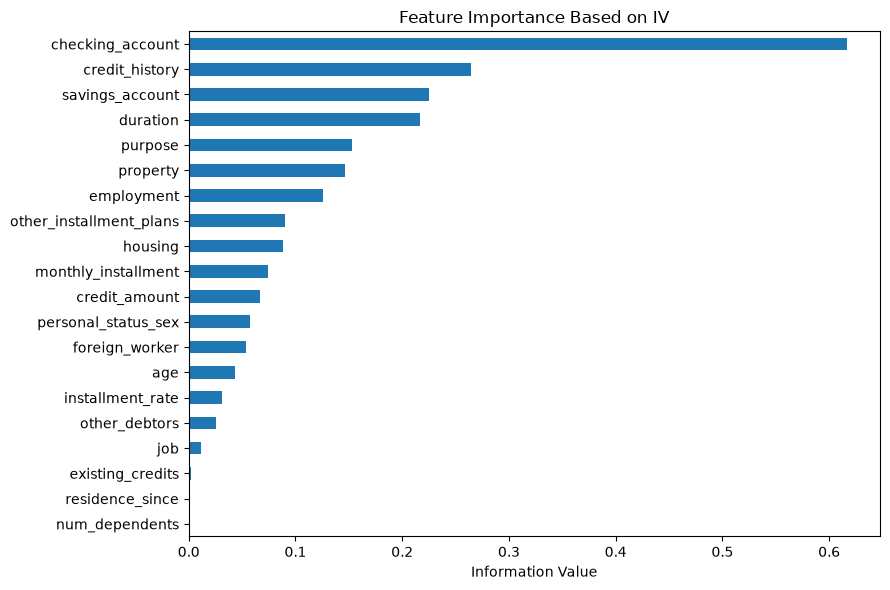

In [27]:
import matplotlib.pyplot as plt

iv_scores.sort_values().plot.barh(figsize=(9, 6))

plt.xlabel("Information Value")
plt.title("Feature Importance Based on IV")
plt.tight_layout()
plt.show()

In [28]:

from sklearn.feature_selection import mutual_info_classif

# Copy training features
X_mi = X_train_fe.copy()

# Define categorical and numerical features
categorical_cols = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "foreign_worker"
]

numerical_cols = [
    col for col in X_mi.columns
    if col not in categorical_cols
]

# Convert categorical features into integer codes
for col in categorical_cols:
    X_mi[col] = pd.factorize(
        X_mi[col],
        sort=True
    )[0]

# Identify discrete and continuous features
discrete_mask = [
    col in categorical_cols
    for col in X_mi.columns
]

# Calculate Mutual Information
mi = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

# Rank features
mi_scores = pd.Series(
    mi,
    index=X_mi.columns,
    name="Mutual Information"
).sort_values(ascending=False)

print(mi_scores)


checking_account           0.060835
installment_rate           0.032107
residence_since            0.030742
credit_history             0.027320
credit_amount              0.023043
savings_account            0.022290
monthly_installment        0.016734
purpose                    0.015891
property                   0.015343
employment                 0.013298
other_installment_plans    0.009675
housing                    0.009350
personal_status_sex        0.006083
foreign_worker             0.004831
duration                   0.004252
other_debtors              0.002717
job                        0.001220
existing_credits           0.000859
age                        0.000000
num_dependents             0.000000
Name: Mutual Information, dtype: float64


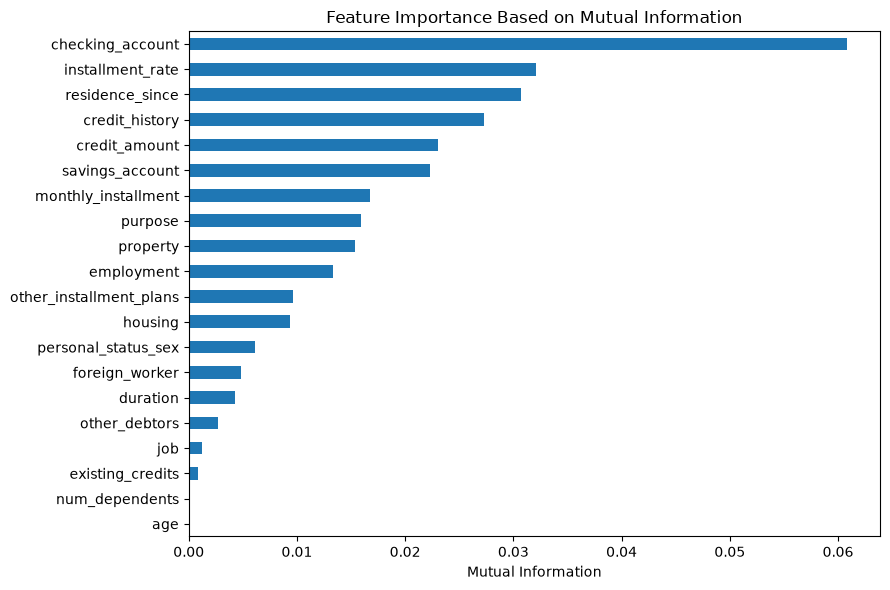

In [29]:
mi_scores.sort_values().plot.barh(figsize=(9, 6))

plt.xlabel("Mutual Information")
plt.title("Feature Importance Based on Mutual Information")
plt.tight_layout()
plt.show()

In [30]:

def oof_target_auc(values, target, n_splits=5, random_state=42):
    """Leakage-free univariate AUC for a categorical feature: out-of-fold target encoding."""
    oof = np.zeros(len(target))

    folds = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    for fit_idx, score_idx in folds.split(values, target):
        rates = (
            pd.Series(target.iloc[fit_idx].to_numpy())
            .groupby(values.iloc[fit_idx].to_numpy())
            .mean()
        )

        oof[score_idx] = (
            values.iloc[score_idx]
            .map(rates)
            .fillna(target.iloc[fit_idx].mean())
            .to_numpy()
        )

    return roc_auc_score(target, oof)


# 1. Calculate AUC for all features
auc_rows = []

for col in X_train_fe.columns:
    if col in categorical_cols:
        auc = oof_target_auc(X_train_fe[col], y_train)
        kind = "categorical"
        direction = "category-level"
    else:
        auc = roc_auc_score(y_train, X_train_fe[col])
        kind = "numeric"
        direction = (
            "higher -> higher risk"
            if auc >= 0.5
            else "higher -> lower risk"
        )

    auc_rows.append({
        "Feature": col,
        "Type": kind,
        "AUC": max(auc, 1 - auc),
        "Direction": direction,
    })

auc_table = pd.DataFrame(auc_rows)


# 2. Use previously calculated Mutual Information scores
# mi_scores was calculated in the first code block


# 3. Calculate Random Forest feature importance
rf_screen = RandomForestClassifier(
    n_estimators=500,
    max_depth=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

rf_screen.fit(X_train_processed, y_train)

rf_importance = pd.Series(
    rf_screen.feature_importances_,
    index=X_train_processed.columns,
)


def parent_feature(name):
    for col in nominal_cols:
        if name.startswith(f"{col}_"):
            return col
    return name


rf_importance = (
    rf_importance
    .groupby(rf_importance.index.map(parent_feature))
    .sum()
)


# 4. Combine all feature-ranking metrics
feature_ranking = (
    auc_table
    .assign(
        MI=auc_table["Feature"].map(mi_scores),
        RF_importance=auc_table["Feature"].map(rf_importance),
    )
    .sort_values("AUC", ascending=False)
    .reset_index(drop=True)
)

feature_ranking.round(3)


,Feature,Type,AUC,Direction,MI,RF_importance
0,checking_account,categorical,0.685,category-level,0.061,0.220
1,duration,numeric,0.629,higher -> higher risk,0.004,0.088
2,credit_history,categorical,0.595,category-level,0.027,0.079
3,property,categorical,0.574,category-level,0.015,0.052
4,employment,categorical,0.566,category-level,0.013,0.046
5,monthly_installment,numeric,0.566,higher -> lower risk,0.017,0.078
6,savings_account,categorical,0.562,category-level,0.022,0.050
7,age,numeric,0.552,higher -> lower risk,0.000,0.051
8,purpose,categorical,0.550,category-level,0.016,0.061
9,housing,categorical,0.548,category-level,0.009,0.030


### 2.3 The Three Key Discriminators

To identify the three features with the greatest power to distinguish between "Good" (reliable) and "Bad" (unreliable/defaulting) customers, four complementary metrics were employed: **Information Value (IV)**, **Mutual Information (MI)**, **Univariate ROC-AUC**, and **Random Forest Feature Importance**. These metrics examine different facets of the relationship between the features and the target variable: AUC assesses the discriminative power of each feature in isolation. MI measures the information a feature provides regarding default status; IV evaluates the ability to separate the two groups. and Random Forest Importance assesses the role of a feature when considered alongside other variables.

Based on the aggregate results of these evaluations, three features—`checking_account`, `credit_history`, and `savings_account`—were selected as key features. This selection is supported, in particular, by high IV and MI values, as well as strong performance across the other supplementary evaluations.

**1. Checking Account**

This feature demonstrated the strongest discriminative power among all those analyzed. It yielded an AUC of 0.685 and an IV of 0.617, while also ranking highest in terms of both MI and Random Forest Importance. The status of a checking account can provide insight into an applicant's liquidity and short-term financial capacity. For instance, individuals with a more favorable checking account balance may possess a greater ability to manage their financial obligations. Consequently, this feature serves as a significant indicator for distinguishing between "Good" and "Bad" customers.

**2. Credit History**

Credit history reflects how an applicant has managed their financial and credit obligations in the past. This feature ranked highly in both IV (Information Value) and MI (Mutual Information) assessments, achieving an AUC value of 0.595. Past credit behavior can provide valuable insights into future loan repayment patterns. For instance, a history of consistent, timely repayments—as opposed to an unfavorable credit record—can indicate a significant difference in the level of default risk. Consequently, credit history serves as a key indicator when assessing the risk profile of applicants.

**3. Savings Account Status**

The status of an applicant's savings account offers a glimpse into their accumulated financial resources and economic stability. This feature performed strongly in IV and MI calculations; an MI value of 0.022 suggests it contains meaningful information regarding default risk. Furthermore, an AUC of 0.562, combined with its positive importance score in a Random Forest model, indicates that this feature—beyond its independent statistical association with the target variable—contributes effectively to predictive modeling when considered alongside other features. Individuals with higher savings are generally better equipped to manage their financial obligations when faced with unforeseen expenses or temporary drops in income.

**Conclusion**

The results of this analysis indicate that current account status, credit history, and savings account status are among the most significant features for distinguishing between "good" (reliable) and "bad" (unreliable) borrowers within the German Credit dataset. These three features were selected based on a simultaneous evaluation of multiple statistical and model-based criteria, ensuring that the selection process does not rely on a single assessment method alone. It should be noted, however, that these findings reflect statistical associations and predictive power; they do not, in themselves, establish a direct cause-and-effect relationship. Furthermore, the ultimate importance of these features should also be examined in the performance of the predictive model.

In [31]:
top3_text = ", ".join(
    f"{row.Feature} ({row.AUC:.3f})"
    for row in feature_ranking.head(3).itertuples()
)

task2_summary = pd.DataFrame({
    "Deliverable": [
        "Train/test split",
        "Missing-data handling",
        "Encoding",
        "Scaling",
        "Engineered features",
        "Processed matrices",
        "Top 3 discriminators",
    ],
    "Result": [
        f"{len(X_train):,} train / {len(X_test):,} test (80/20), stratified; "
        f"default rate {y_train.mean():.1%} train / {y_test.mean():.1%} test",
        f"{int(X_train_fe.isna().sum().sum() + X_test_fe.isna().sum().sum())} missing cells; "
        "median/mode imputers fitted on train only (no-op here)",
        f"{len(nominal_cols)} nominal one-hot ({n_onehot} columns) + "
        f"{len(ordinal_cols)} ordinal ({len(ordinal_cols)} columns)",
        "StandardScaler fitted on X_train_fe, applied to both sets",
        "monthly_installment = credit_amount / duration; "
        "loan_to_income = duration x installment_rate / 100",
        f"{X_train_processed.shape[0]} x {X_train_processed.shape[1]} train; "
        f"{X_test_processed.shape[0]} x {X_test_processed.shape[1]} test; 0 missing",
        top3_text,
    ],
})

task2_summary

,Deliverable,Result
0,Train/test split,"800 train / 200 test (80/20), stratified; defa..."
1,Missing-data handling,0 missing cells; median/mode imputers fitted o...
2,Encoding,9 nominal one-hot (38 columns) + 3 ordinal (3 ...
3,Scaling,"StandardScaler fitted on X_train_fe, applied t..."
4,Engineered features,monthly_installment = credit_amount / duration...
5,Processed matrices,800 x 49 train; 200 x 49 test; 0 missing
6,Top 3 discriminators,"checking_account (0.685), duration (0.629), cr..."


# PART 3:

best hyper parameter for Random Forest: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 200}


,Model,ROC-AUC,PR-AUC
0,Baseline (Decision Tree),0.7231,0.4924
1,Challenger (Random Forest Tuned),0.8310,0.7053


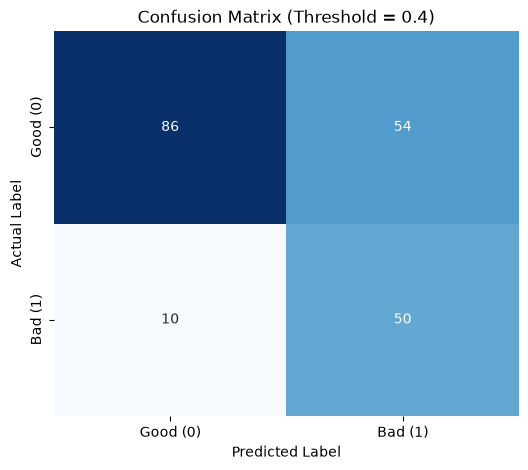

In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

dt_baseline = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt_baseline.fit(X_train_processed, y_train)

rf_challenger = RandomForestClassifier(random_state=42, class_weight='balanced')


param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=rf_challenger,
    param_grid=param_grid,
    scoring='average_precision',  
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_train)
best_rf = grid_search.best_estimator_

print("best hyper parameter for Random Forest:", grid_search.best_params_)

models = {
    "Baseline (Decision Tree)": dt_baseline,
    "Challenger (Random Forest Tuned)": best_rf
}

evaluation_results = []

for name, model in models.items():
    y_pred_proba = model.predict_proba(X_test_processed)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    pr_auc = average_precision_score(y_test, y_pred_proba)
    
    evaluation_results.append({
        "Model": name,
        "ROC-AUC": round(roc_auc, 4),
        "PR-AUC": round(pr_auc, 4)
    })

import pandas as pd
df_results = pd.DataFrame(evaluation_results)
display(df_results)

final_model = best_rf
threshold = 0.4
y_test_proba = final_model.predict_proba(X_test_processed)[:, 1]
y_test_pred_custom = (y_test_proba >= threshold).astype(int)

cm = confusion_matrix(y_test, y_test_pred_custom)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Good (0)', 'Bad (1)'],
            yticklabels=['Good (0)', 'Bad (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title(f'Confusion Matrix (Threshold = {threshold})')
plt.show()

Analysis of the Balance Between Error Rates (False Positives vs. False Negatives)
False Negatives (10):
Concept: Granting credit facilities to customers who will ultimately default.
Consequence: This is the most costly type of error for a bank, as it results in the loss of both the principal loan amount and the accrued interest for each instance.
Analysis in this model: The very low number of such errors (only 10 out of 60 high-risk customers) indicates that the model has been highly aggressive and successful in identifying delinquent borrowers, significantly reducing the risk of lending to individuals who will default.
False Positives (54):
Concept: Rejecting applications from customers who are, in reality, creditworthy (good borrowers).
Consequence: This error represents an "opportunity cost".the bank loses out on qualified, profitable customers and cedes market share to competitors.
Analysis in this model: The relatively high number of such errors (54 out of 140 creditworthy customers) suggests that the model has adopted a conservative stance, driven by the threshold setting of 0.4 .This threshold reflects a "risk-averse" policy; in this approach, risk management has prioritized minimizing the number of high-risk borrowers who pass the bank's screening process (drastically reducing False Negatives), even at the cost of mistakenly rejecting a number of creditworthy customers (increasing False Positives).

### XAI

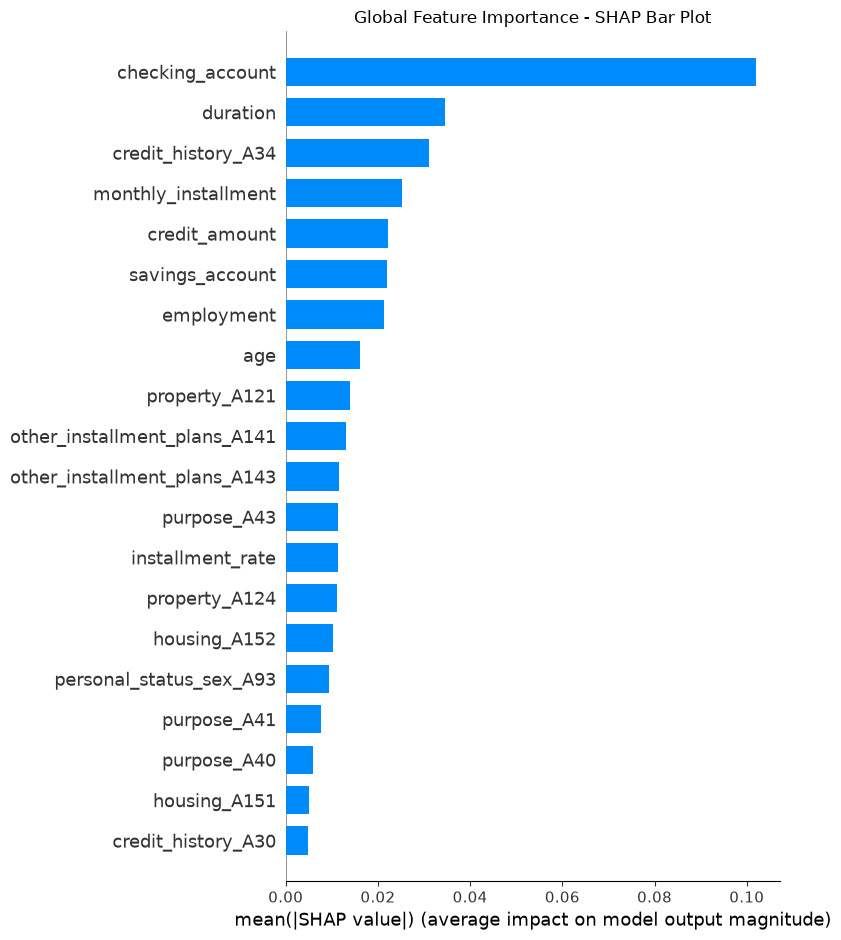

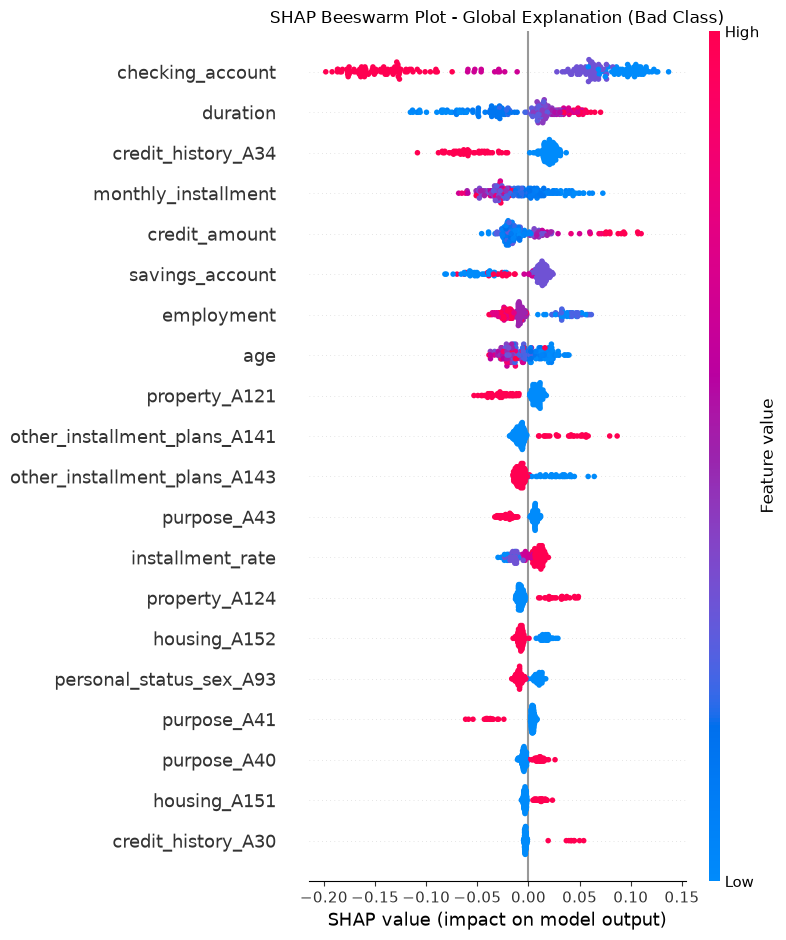

--- Low-Risk Customer Analysis (Test Index: 1) ---


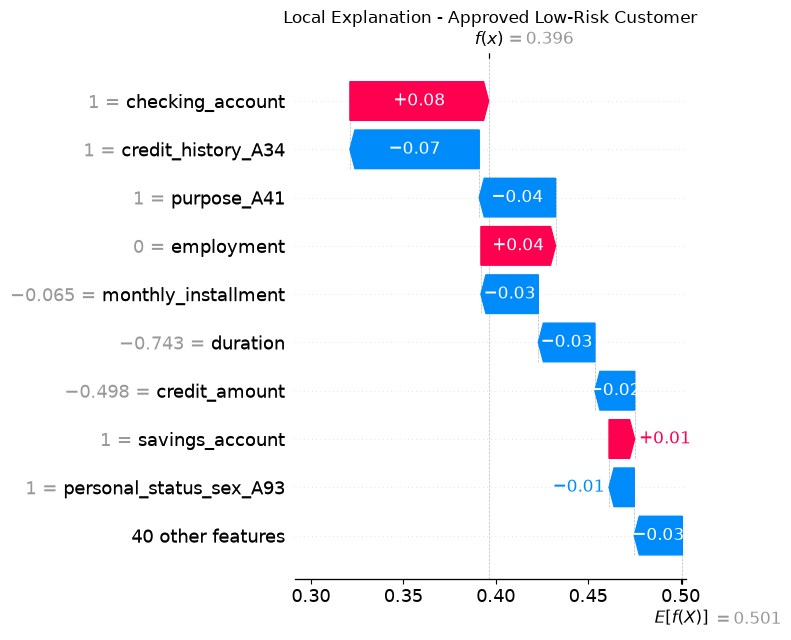

--- Rejected High-Risk Customer Analysis (Test Index: 0) ---


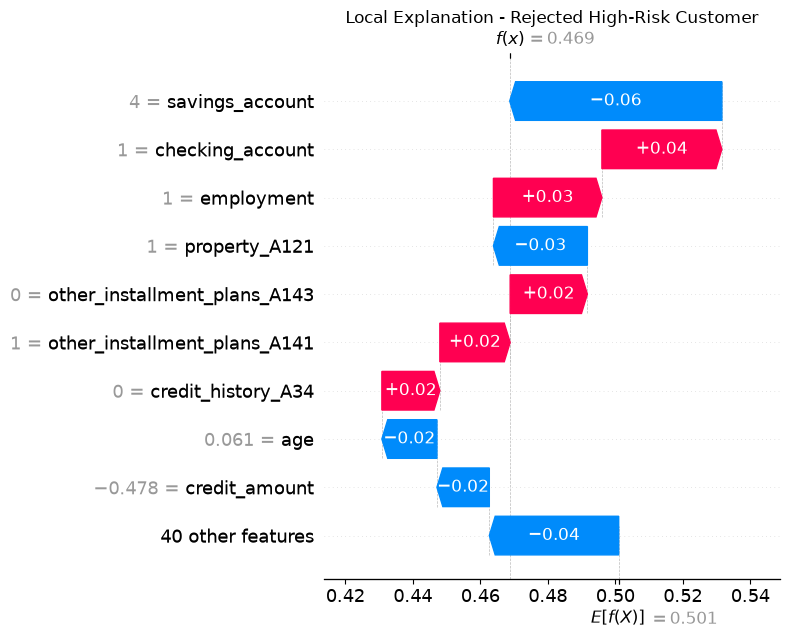


--- LIME Comparison for High-Risk Customer (Test Index: 0) ---


c:\Users\OK\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


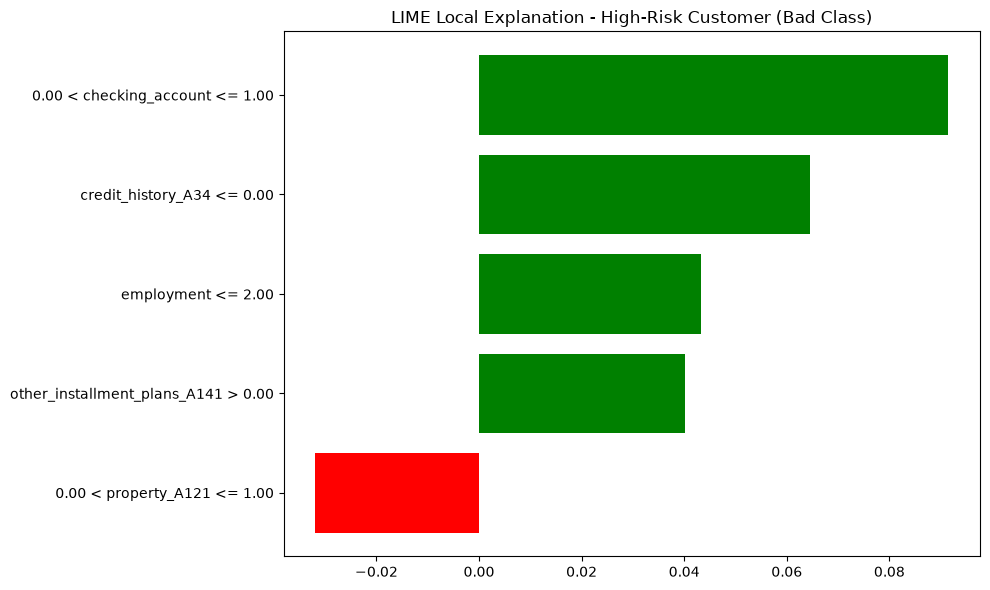

In [36]:

import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ----------------------------------------------------
# 1. GLOBAL EXPLANATION - SHAP
# ----------------------------------------------------

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_test_processed)

# Select SHAP values for the Bad (1) class
shap_values_bad = shap_values[:, :, 1]

# Global Feature Importance - Bar Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_bad,
    X_test_processed,
    plot_type="bar",
    show=False
)
plt.title("Global Feature Importance - SHAP Bar Plot")
plt.tight_layout()
plt.show()

# Global Feature Impact - Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_bad,
    X_test_processed,
    show=False
)
plt.title("SHAP Beeswarm Plot - Global Explanation (Bad Class)")
plt.tight_layout()
plt.show()


# ----------------------------------------------------
# 2. LOCAL EXPLANATION - SHAP
# ----------------------------------------------------

# Predict customer risk probabilities
y_pred_proba = final_model.predict_proba(X_test_processed)[:, 1]

# Apply classification threshold
predicted_labels = (y_pred_proba >= 0.4).astype(int)

# Identify low-risk and high-risk customers
low_risk_indices = np.where(predicted_labels == 0)[0]
high_risk_indices = np.where(predicted_labels == 1)[0]

# Select one sample from each group
if len(low_risk_indices) == 0 or len(high_risk_indices) == 0:
    raise ValueError(
        "Both low-risk and high-risk customers must exist in the test set."
    )

sample_good_idx = low_risk_indices[0]
sample_bad_idx = high_risk_indices[0]


# Local Explanation - Approved Low-Risk Customer
print(
    f"--- Low-Risk Customer Analysis "
    f"(Test Index: {sample_good_idx}) ---"
)

plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap_values_bad[sample_good_idx],
    show=False
)
plt.title("Local Explanation - Approved Low-Risk Customer")
plt.tight_layout()
plt.show()


# Local Explanation - Rejected High-Risk Customer
print(
    f"--- Rejected High-Risk Customer Analysis "
    f"(Test Index: {sample_bad_idx}) ---"
)

plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap_values_bad[sample_bad_idx],
    show=False
)
plt.title("Local Explanation - Rejected High-Risk Customer")
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# 3. LOCAL COMPARISON - LIME (OPTIONAL)
# ----------------------------------------------------

# استفاده از X_train_processed چون تمام ستون‌ها در آن عددی/باینری هستند
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train_processed),
    feature_names=X_train_processed.columns.tolist(),
    class_names=['Good (0)', 'Bad (1)'],
    mode='classification',
    random_state=42
)

# Explain the rejected high-risk customer using LIME
print(
    f"\n--- LIME Comparison for High-Risk Customer "
    f"(Test Index: {sample_bad_idx}) ---"
)

exp = lime_explainer.explain_instance(
    data_row=X_test_processed.iloc[sample_bad_idx].values,
    predict_fn=final_model.predict_proba,
    num_features=5,
    labels=(1,)
)

# Display LIME explanation
fig = exp.as_pyplot_figure(label=1)
fig.set_size_inches(10, 6)
plt.title("LIME Local Explanation - High-Risk Customer (Bad Class)")
plt.tight_layout()
plt.show()

As shown in the SHAP bar plot, the top three features influencing the model are "checking_account," "duration," and "credit_history_A34." Furthermore, an examination of the beeswarm plot reveals the following:
The "checking_account" feature not only ranks highest on the plot but also exhibits the greatest horizontal spread; this indicates significant variation and a substantial impact on the model's output. Additionally, the points on the left are red, while those on the right are blue, signifying an inverse relationship between this feature and the target class.
The "duration" feature ranks second. Here, red points appear on the right and blue points on the left, suggesting a roughly direct relationship between this feature and the target class. The "credit_history_A34" feature follows a similar pattern and ranks third on the plot.
################################################################

Analysis of Figure and Behavior for  Approved Customer:

Model Base Value (E[f(x)] = 0.501): This represents the baseline average default risk across the entire model.
Final Prediction (f(x) = 0.396): This is the specific risk score for this customer. Since this figure falls below the decision threshold (0.4), their loan application has been approved.
Risk-Reducing Factors (Contributing to Loan Approval):
Credit History (`credit_history_A34`): Impact of -0.07 (the most significant positive factor for approval).
Loan Purpose (`purpose_A41`): Impact of -0.04.
Loan Duration and Monthly Installment: Each has an impact of -0.03.
Loan Amount (`credit_amount`): Impact of -0.02.
Risk-Increasing Factors (Minor Obstacles):
Checking Account Status (`checking_account`): Impact of +0.08 (the primary factor increasing risk for this individual).
Employment Status (`employment`): Impact of +0.04.
Numerical Conclusion: Although the checking account status (+0.08) increased the risk, an excellent credit history (-0.07) and other favorable conditions brought the final score down from 0.501 to 0.396, resulting in the approval of the loan.

############################################################################
Analysis of Figure and Behavior for Rejected Customer:
Model Base Value (E[f(x)] = 0.501): This represents the baseline average default risk across the entire model.
Final Prediction (f(x) = 0.469): This is the specific risk score for this customer.

Risk-Reducing Factors:
Savings Account (savings_account): Impact of -0.06 (the most significant factor reducing risk).
Property Type (property_A121): Impact of -0.03.
Age (age) and Credit Amount (credit_amount): Each with an impact of -0.02.
Other Features: Impact of -0.04.

Risk-Increasing Factors (Pushing toward Rejection):
Checking Account Status (checking_account): Impact of +0.04.
Employment Status (employment): Impact of +0.03.
Other Installment Plans (other_installment_plans): Impacts of +0.02 and +0.02.
Credit History (credit_history_A34): Impact of +0.02.

Numerical Conclusion: Although certain positive attributes like the savings account (-0.06) attempted to lower the risk score, critical risk-increasing elements such as the checking account status (+0.04) and employment status (+0.03) drove the final outcome, resulting in the rejection of the loan application.


##################################################################
Regarding the two analyzed customers, it can be argued that neither could be clearly classified as extremely high-risk or extremely low-risk from a statistical perspective, as their scores were very close to the model's decision threshold. Nevertheless, they were selected and examined as two representative examples.


################################################################
Analysis of Figure and Behavior for LIME High-Risk Customer:
Model Local Explanation Overview: This chart illustrates how specific feature ranges for this individual data point contributed to classifying the customer into the high-risk (Bad) category.   
image_7d4673.png

Risk-Increasing Factors (Green Bars Supporting Bad Class):
Checking Account (0.00 < checking_account <= 1.00): With an impact weight of approximately +0.09, this is the most dominant feature pushing the model toward the high-risk prediction.
Credit History (credit_history_A34 <= 0.00): Impact weight of about +0.065, showing a strong contribution to the risk score.
Employment (employment <= 2.00): Impact weight around +0.043, increasing the default probability.
Other Installment Plans (other_installment_plans_A141 > 0.00): Impact weight of approximately +0.04.

Risk-Reducing Factor (Red Bar Opposing Bad Class):
Property (0.00 < property_A121 <= 1.00): Impact weight of around -0.03, acting as a mitigating factor that slightly resists the high-risk classification.

Numerical and Model Conclusion: The LIME local approximation confirms that key drivers like checking account status and credit history heavily outweighed positive indicators like property ownership, leading the model to classify this instance securely as a high-risk customer.

In [43]:

# Extract SHAP values for the selected high-risk customer
local_shap_values = shap_values_bad[sample_bad_idx]

# Create a numerical explanation table
shap_results = pd.DataFrame({
    'Feature': X_test_processed.columns,
    'Feature_Value': X_test_processed.iloc[sample_bad_idx].values,
    'SHAP_Value': local_shap_values.values
})

# Sort features by absolute SHAP importance
shap_results['Absolute_SHAP'] = shap_results['SHAP_Value'].abs()

shap_results = shap_results.sort_values(
    by='Absolute_SHAP',
    ascending=False
)
with open("SHAP_High_Risk_Customer.txt", "w", encoding="utf-8") as file:
    file.write("SHAP Numerical Explanation - High-Risk Customer\n")
    file.write("=" * 60 + "\n")
    file.write(shap_results.to_string(index=False))
    file.write("\n\n")
    file.write(f"Base Value: {local_shap_values.base_values}\n")
    file.write(f"Predicted Bad Probability: {y_pred_proba[sample_bad_idx]:.4f}\n")

print("SHAP results successfully saved to SHAP_High_Risk_Customer.txt")

SHAP results successfully saved to SHAP_High_Risk_Customer.txt


#PART 4:


#### Data Context & Empirical Baseline

The dataset consists of $n = 1000$ instances and $p = 20$ raw features (7 numerical and 13 categorical) with an imbalanced target ratio of 70% creditworthy (Good) to 30% default (Bad). Statistical and exploratory analysis confirms that categorical attributes contain the strongest predictive signals—most notably `checking_account` (Cramér's V = 0.352, where negative balance A11 yields a 49.3% default rate versus 11.7% for A14) and `credit_history` (Cramér's V = 0.248).

#### 1. Interpretation of Causality vs. Correlation

When analyzing the model's output and SHAP values, it is essential to distinguish between direct causes of default and statistical proxies (confounders):

* **Direct Causes:** Features such as `credit_amount` and `duration` directly impact default risk by imposing a heavy financial burden and monthly cash flow pressure on the borrower.
* **Statistical Proxies (Confounders):** Features such as `age`, `housing`, or `job` do not inherently cause default. Instead, they act as proxies (or symptoms) for unobserved hidden factors—such as **true income stability and financial capacity**—that correlate with both demographic features and the likelihood of default.



#### 2. Operational Decision-Making and Intervention Risks

* **Feasible Policy Targets:** If a risk manager intends to intervene and reduce default rates, policies must target actionable and direct structural factors (such as managing the `monthly_installment` relative to declared income or adjusting loan duration/structure), rather than superficial proxies.
* **The Danger of Relying on Correlation:** Relying blindly on purely correlated proxy features (e.g., penalizing applicants based on age or housing type) is highly dangerous and ineffective. Because these proxies are not the root causes of default, intervening on them will not reduce actual portfolio risk, while exposing the bank to severe regulatory non-compliance, legal challenges, and the loss of creditworthy customers.